# DINGO MCMC with Gaussian center and inclination priors

Fit the same simple three-file R+C model while **sampling $x_0$, $y_0$, and $i$**. No earlier fits or candidate search are required. Use the **grism** kernel. The import block reloads the Python interface so the new arguments are available in an existing kernel.

The eight sampled parameters are $V_\infty$ (km/s), turnover radius (pixels), center $x_0,y_0$ (pixels), cutout orientation, inclination, and the two R registration offsets (pixels). Intrinsic dispersion is zero. The posterior includes center and inclination uncertainty **under the chosen priors**.


In [5]:
from pathlib import Path
import os
import sys
import logging
import importlib
import matplotlib.pyplot as plt
from IPython.display import display

# Change these paths on another computer. No saved fits are read from them.
REPO = Path("/home/aakavan/kinematics/grism-kinematics")
DATA_DIR = REPO / "data"
CALIBRATION_DIR = REPO.parent / "grism_cal"
OUTPUT_ROOT = REPO.parent / "field_kinematics/edr_kinematics/PaA/dingo_runs"

sys.path.insert(0, str(REPO))
os.environ["GRISM_CAL_DIR"] = str(CALIBRATION_DIR)
# Keep warnings visible; progress bars report the sampling steps.
logging.getLogger("dingo.fitting").setLevel(logging.WARNING)
from dingo import simple_mcmc as sm
sm = importlib.reload(sm)

print("Code:", sm.__file__)
print("Output root:", OUTPUT_ROOT)

Code: /home/aakavan/kinematics/grism-kinematics/dingo/simple_mcmc.py
Output root: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs


## 1. Set the priors and starting fit

`CENTER_MEAN` is the assumed galaxy center in **absolute, zero-based R/C stack pixels**. `(40, 40)` is the geometric midpoint of an 81×81 cutout; it is not automatically a measured imaging center. Inspect the source and update this assumption if needed.

`CENTER_SIGMA_PIXELS = 1.0` gives each coordinate an independent Gaussian prior with a 1-pixel standard deviation. This is a sensitivity experiment, not a measured centering error. Set it to `2.0` for the wider comparison; the run name changes automatically so both experiments are retained. Inclination is sampled with the explicit prior $75^\circ\pm5^\circ$; this block does not load an imaging fit.

The starting values remain explicit numbers. The center prior mean and `start_center` are separate arguments, although we use the same value here. Setting a `fixed_*` argument to a number instead holds that parameter fixed and removes its prior.

Products go to `OUTPUT_ROOT/source_ID/run_name/`. `overwrite=True` replaces only that named experiment. The previous fixed-center runs have different names and remain available. Use a new run name when comparing other settings, such as a different prior mean or inclination.


ID6170: explicit V_inf=450 km/s; initial i=75 deg; prior i=75 +/- 5 deg.
Saving to /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/gaussian_center_s1_i75_centered_v450
Sampled x0: Gaussian prior 40 +/- 1 pixels (1 sigma).
Sampled y0: Gaussian prior 40 +/- 1 pixels (1 sigma).
Sampled parameters: ['velocity.V_rot', 'velocity.R_v', 'velocity.x0_v', 'velocity.y0_v', 'velocity.theta_v', 'velocity.inc_v', 'image.R.dx', 'image.R.dy']


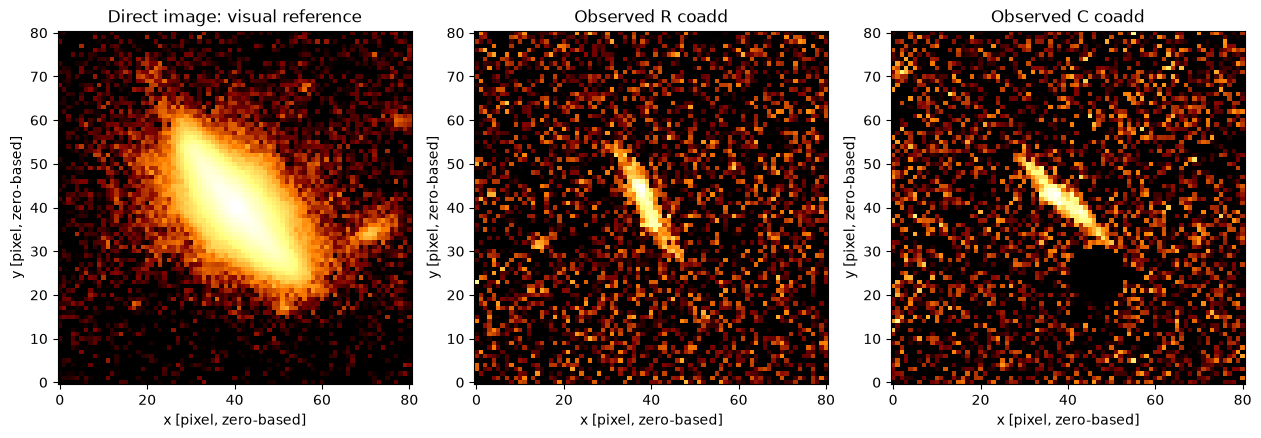

In [ ]:
CENTER_MEAN = (40.0, 40.0)  # Assumed center in R/C stack pixels; check against the image
CENTER_SIGMA_PIXELS = 1.0    # 1-sigma per coordinate; change to 2.0 for a separate comparison
# RUN_NAME = f"gaussian_center_s{CENTER_SIGMA_PIXELS:g}_i75_centered_v450"
RUN_NAME = "fixed_xy40_sampled_i_test1"

run = sm.prepare(
    6170,
    data_dir=DATA_DIR,
    output_root=OUTPUT_ROOT,
    run_name=RUN_NAME,
    overwrite=True,
    device="cuda",                 # or "cpu"

    fixed_x0=40.0,                 # Sample x0 with its Gaussian prior
    fixed_y0=40.0,                 # Sample y0 with its Gaussian prior
    start_center=CENTER_MEAN,
    center_mean=CENTER_MEAN,
    center_sigma=CENTER_SIGMA_PIXELS,

    fixed_inclination=None,        # Sample i with the Gaussian prior below
    start_inclination=75.0,
    inclination_mean=75.0,
    inclination_sigma=5.0,         # 1-sigma, degrees

    start_velocity=450.0,          # Sampled V_inf, km/s
    start_turnover=10.09,          # Sampled R_t, pixels
    start_pa=286.64,               # Sampled cutout orientation, degrees
    start_offset=(1.0625, 0.2852),  # Sampled R registration dx,dy, pixels
    max_velocity=1000.0,
)
print("Sampled parameters:", run.fitter.mcmc_param_names)
fig = sm.show_inputs(run)
display(fig)
plt.close(fig)


## 2. Fit and inspect residuals

This optional local optimization fits all sampled parameters, including center and inclination, using the same posterior as MCMC. The cyan cross marks the fitted kinematic center. Skip `sm.fit_local(...)` to sample directly from the explicit starting values.


Local fit evaluations:   0%|          | 0/3000 [00:00<?, ?it/s]

Local fit: Optimization terminated successfully. (121 evaluations).


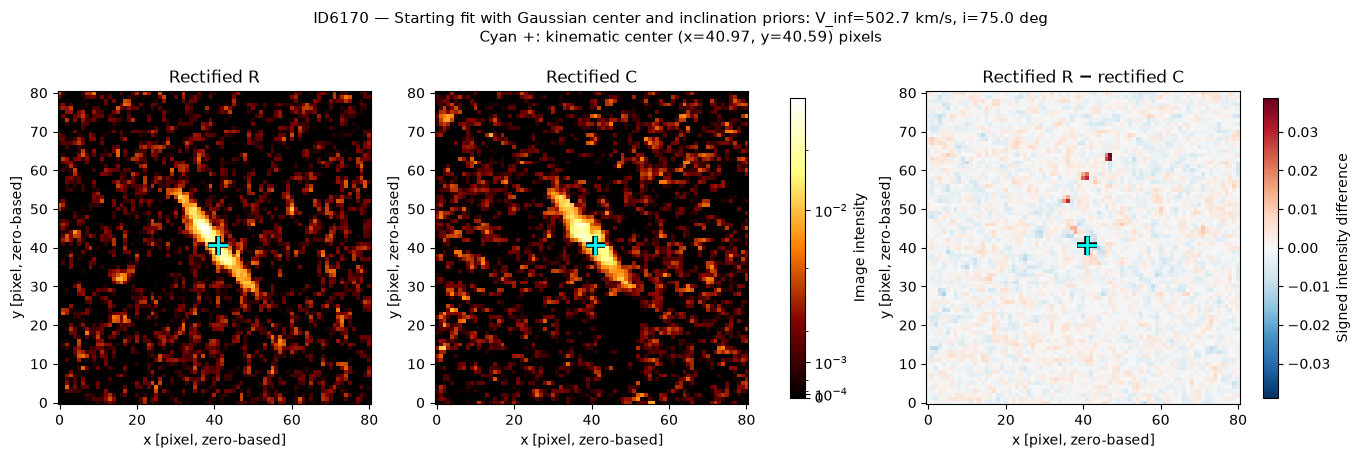

In [7]:
fit_status = sm.fit_local(run, max_evaluations=3000)
fig = sm.show_fit(run, label="Starting fit with Gaussian center and inclination priors")
display(fig)
fig.savefig(run.directory / "starting_fit.png", dpi=150, bbox_inches="tight")
plt.close(fig)

## 3. Run MCMC

This experiment uses 1,000 discarded warmup steps and 4,000 retained steps per walker, with 64 walkers. These are editable sampling budgets, not a guarantee of convergence: inspect all walkers and the saved diagnostics. For a quick execution check use `warmup=100, draws=200, walkers=32`.

Progress bars and checkpoints work as in the simple notebook. Sampling uses emcee with the PyTorch likelihood batched on the GPU.


In [8]:
RESULT_DIR = sm.sample(
    run,
    warmup=500,
    draws=2000,
    walkers=64,
    seed=42,
    progress="notebook",           # use True for a text progress bar
)
print(RESULT_DIR)

Warmup:   0%|          | 0/500 [00:00<?, ?it/s]

MCMC draws:   0%|          | 0/2000 [00:00<?, ?it/s]

The chain is shorter than 50 times the integrated autocorrelation time for 8 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 40;
tau: [232.70006093 230.89035329 187.88799526 117.54425683 239.05007657
 135.00978032 218.76910647  66.93773048]


finished: 2000 retained steps per walker.
Results: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/gaussian_center_s1_i75_centered_v450
/home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/gaussian_center_s1_i75_centered_v450


## 4. View saved results

The corner plot includes all sampled parameters, including **$x_0$, $y_0$, and $i$** for this configuration. The table gives pooled medians and 16–84% intervals. Residuals use one actual maximum-posterior sample. Any parameters you explicitly fix are excluded from the corner plot and recorded with the saved results.

To reopen results after restarting, run the imports and this cell with `RESULT_DIR` set below. Do not rerun preparation with `overwrite=True` merely to view results.


Status: finished; retained steps/walker: 2000; latest segment mean acceptance: 0.087
These are conditional posterior summaries. Check traces, bounds and independent starts before quoting errors.
Autocorrelation time per parameter: {'velocity.V_rot': 232.70006093317787, 'velocity.R_v': 230.89035329442652, 'velocity.x0_v': 187.887995256389, 'velocity.y0_v': 117.54425682724872, 'velocity.theta_v': 239.05007657288206, 'velocity.inc_v': 135.00978032385837, 'image.R.dx': 218.76910647253197, 'image.R.dy': 66.93773048073407}


,median,minus_16th,plus_84th,unit
parameter (all walkers pooled),,,,
V_inf,654.674303,160.451708,270.167460,km/s
R_t,18.501573,6.646882,10.033638,pixel
x_center,40.583786,0.701981,0.489486,pixel
y_center,40.694215,0.152884,0.180385,pixel
cutout_PA,289.145465,3.394129,7.995144,deg
inclination,76.348900,3.338330,1.410277,deg
R_x_offset,1.251842,0.065702,0.145614,pixel
R_y_offset,0.281392,0.015996,0.016286,pixel


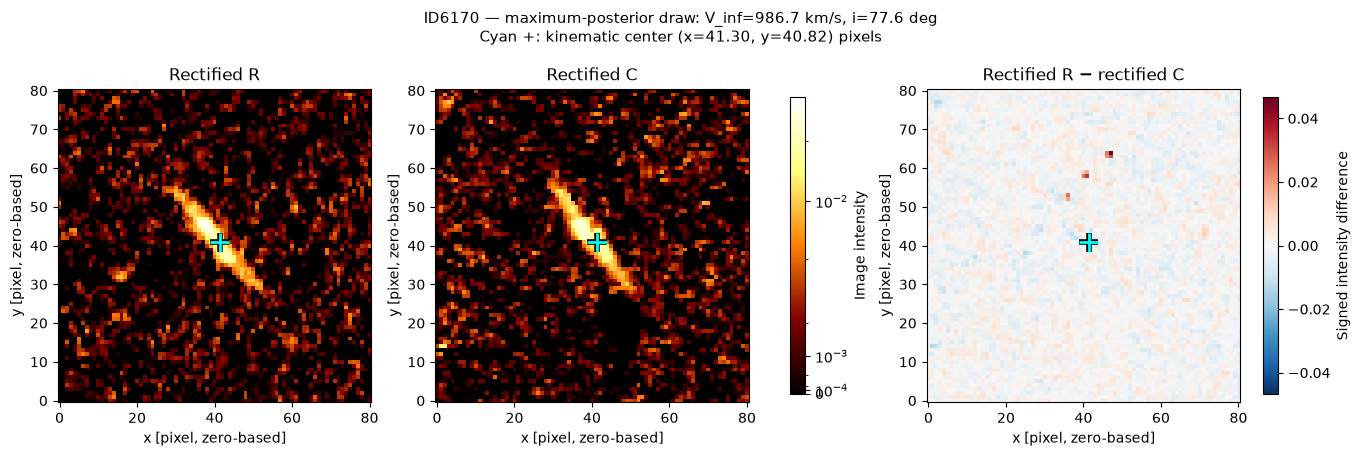

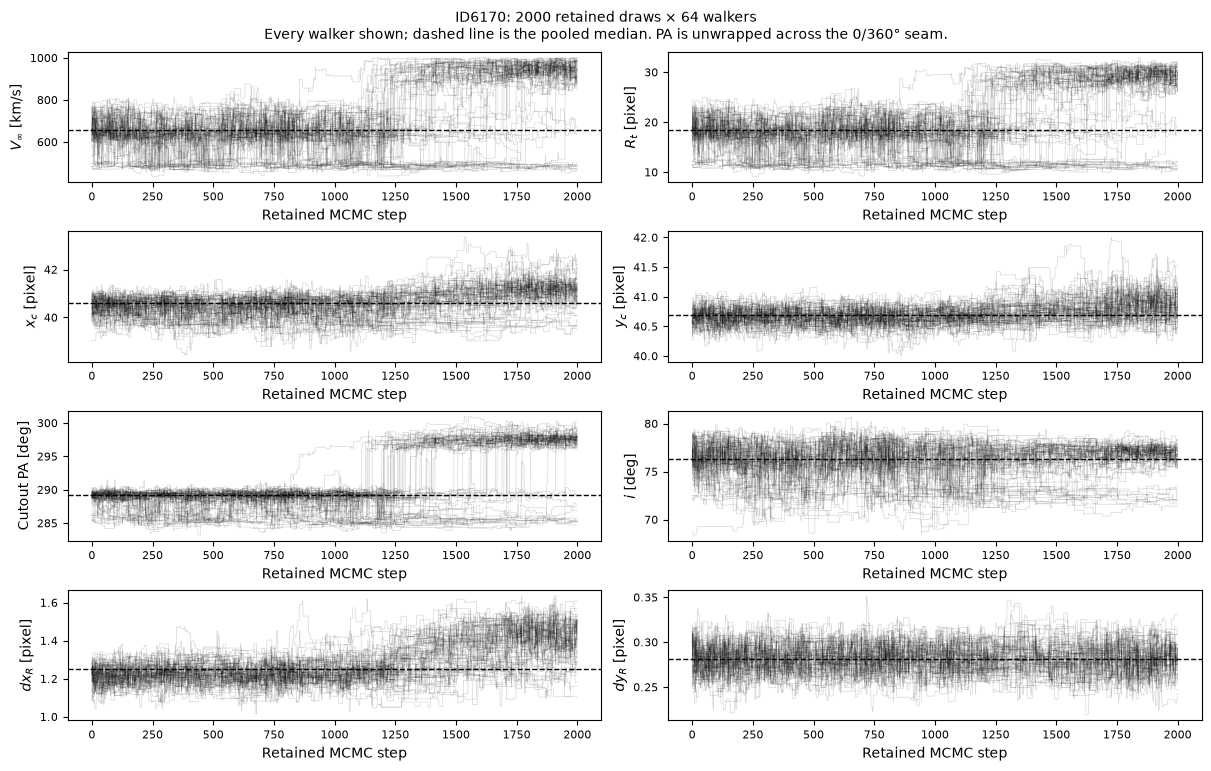

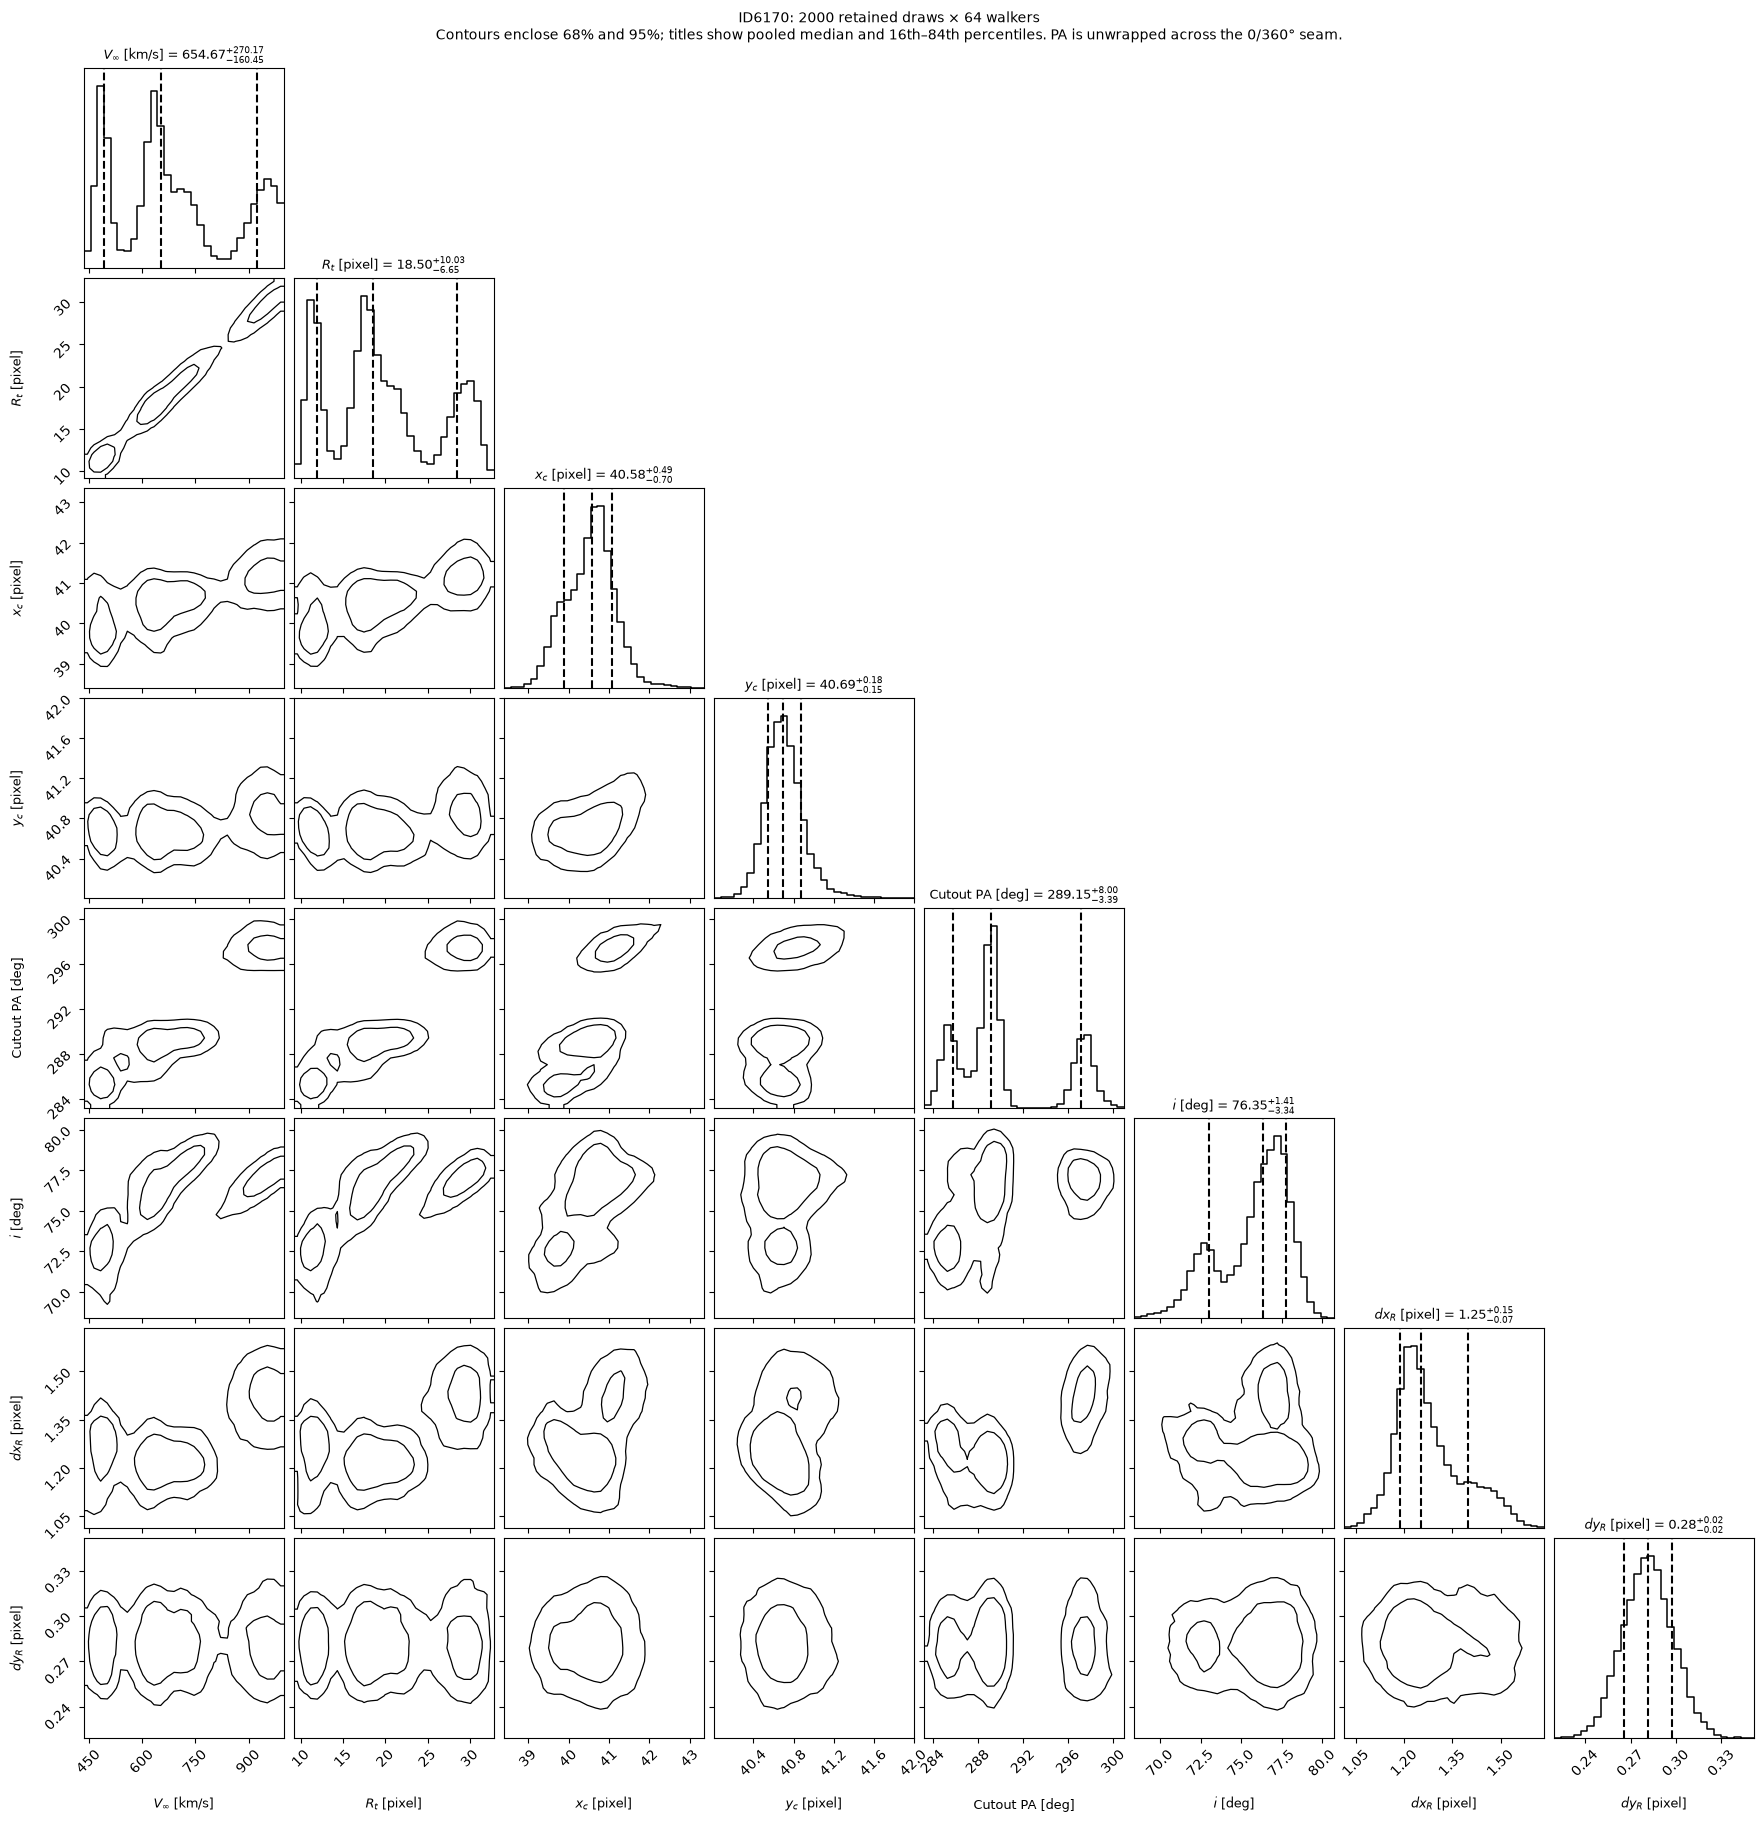

In [9]:
# To open saved results without fitting:
# RESULT_DIR = OUTPUT_ROOT / "6170" / "gaussian_center_s1_i75_v450"
views = sm.show_results(RESULT_DIR)
display(views["summary"])
for name in ("residuals", "traces", "corner"):
    display(views[name])
    plt.close(views[name])

The likelihood is the original full-image squared corrected R−C residual divided by a fixed noise variance estimated from the input stacks. This does not fully propagate coadd/interpolation covariance. Center and inclination Gaussian priors are applied in both local fitting and MCMC; their means and widths are saved in `run_info.txt` and `config.yaml`.

The remaining priors are uniform $V_\infty$ from 0 to `max_velocity`, log-uniform turnover radius from 0.5 pixels to the cutout half-width, full-turn uniform orientation, and Gaussian R registration offsets about zero with width 2 pixels (truncated at ±10). These registration offsets are separate from the kinematic center. Inclination is restricted to 5–85 degrees, and center coordinates retain the existing bounds of ±30 pixels around the cutout midpoint.

A velocity piling up at its bound is still not a measured plateau speed. Inspect residuals, traces and independent starting points before quoting uncertainties.

Results are saved in `OUTPUT_ROOT/source_ID/run_name/`. To resume after a kernel restart: `run = sm.open_run(saved_directory)`, then `sm.sample(run, warmup=1000, draws=8000, walkers=64, resume=True, progress="notebook")`. Keep the saved warmup and walker count; `draws` is the desired total retained length. A different center prior requires a separate experiment, not a resume of the previous chain.


## 5. Convert the saved run to physical units

**These new blocks only read the saved posterior; they do not run optimization or MCMC.** `RESULT_DIR` is the folder selected above. After a kernel restart, set it to the saved run you want before using these blocks.

Redshift is read from this run's saved source metadata. We use **Planck18 angular-diameter distances**, giving proper pc per arcsecond. The R/C FITS cutouts do not contain a pixel scale, so declare the scale of the **R/C stacks**, not the SW imaging used by PySersic. The current native LW cutouts use the adopted value **0.063 arcsec/pixel**. Change it for resampled data.

$$R_t[\mathrm{pc}]=R_t[\mathrm{pixel}]\,s[\mathrm{arcsec/pixel}]\,\mathrm{scale}(z)[\mathrm{pc/arcsec}].$$

Redshift, cosmology and pixel scale are treated as fixed. No lensing correction is applied.

In [10]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from dingo.simple_mcmc_profiles import PhysicalProfiles

# If reopening saved results, set this to your run folder:
# RESULT_DIR = Path("/home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/gaussian_center_s1_i75_v450")
PIXEL_SCALE_ARCSEC = 0.063  # R/C stack scale; do not substitute the F150W imaging scale
physical = PhysicalProfiles(RESULT_DIR, pixel_scale_arcsec=PIXEL_SCALE_ARCSEC)
print(f"ID{physical.source_id}: z = {physical.scale['redshift']:g}; {physical.scale['cosmology']}")
print(f"1 arcsec = {physical.scale['pc_per_arcsec']:,.2f} pc")
print(f"1 R/C pixel = {physical.scale['pc_per_pixel']:,.2f} pc")
print("Reading saved results from:", RESULT_DIR)

ID6170: z = 1.1147; Planck18
1 arcsec = 8,416.91 pc
1 R/C pixel = 530.27 pc
Reading saved results from: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/gaussian_center_s1_i75_centered_v450


## 6. Velocity at the turnover radius, and turnover radius in parsecs

For this arctangent model, **$V(R_t)=V_\infty/2$ exactly**. We compute that velocity and $R_t$ in pc separately for every posterior draw, then report the pooled median and 16th–84th percentile offsets. The velocity is evaluated at **each draw's own turnover radius**, not at the median turnover radius.

The turnover radius may lie outside the well-measured emission. These are model-derived quantities. This configuration propagates the sampled center and inclination uncertainty under the stated priors; fixing a parameter instead excludes its uncertainty.

In [11]:
turnover = physical.turnover_summary(save=True)
display(turnover)

,median,minus_16th,plus_84th,unit
parameter,,,,
turnover_velocity,327.337151,80.225854,135.083730,km/s
turnover_radius_pixels,18.501573,6.646882,10.033638,pixel
turnover_radius_pc,9810.747050,3524.612883,5320.492546,pc


## 7. Rotation curve in physical units

At each common radius, evaluate every paired $(V_\infty,R_t)$ posterior draw before taking percentiles. This preserves their correlation; it is different from inserting two marginal medians into the equation.

The line is the median, the band is the **pointwise 16th–84th percentile interval**, and the vertical marker is the median turnover radius when it falls within the displayed range. `MAX_RADIUS_PIXELS` sets a plotting range, **not a measured emission boundary**; the outer curve can be extrapolated. All velocities are already deprojected.

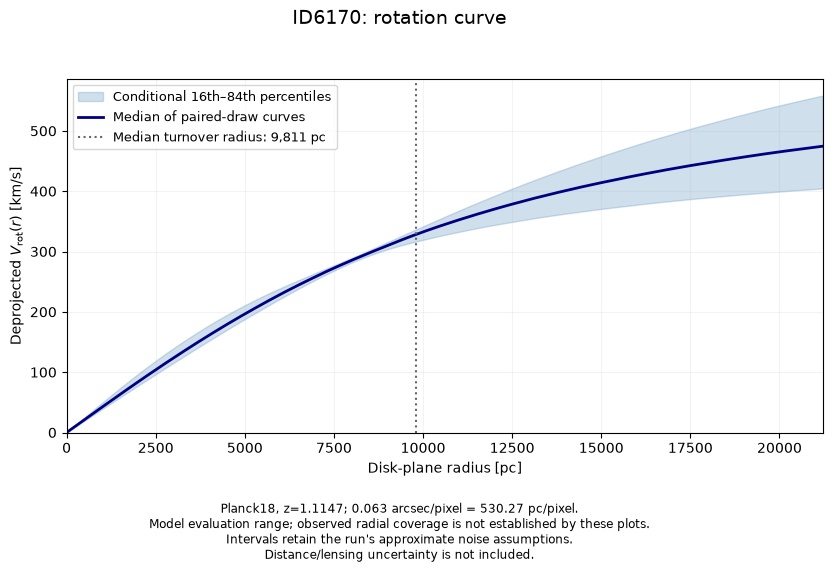

In [12]:
MAX_RADIUS_PIXELS = 40.0  # Display range only; adjust after assessing emission coverage
radii_pc = np.linspace(0.0, MAX_RADIUS_PIXELS * physical.scale["pc_per_pixel"], 161)
fig = physical.rotation_curve(radii_pc, save=True)
display(fig)
plt.close(fig)

## 8. Enclosed dynamical-mass estimate

Use the rotation speed **at each radius**, rather than inserting $V_\infty$ everywhere:

$$M_{\mathrm{dyn,sph}}(<r)=\frac{r\,V_{\mathrm{rot}}(r)^2}{G}.$$

This is a **rotation-only, spherical-equivalent enclosed-mass estimate**: it assumes rotation traces circular support and uses the spherical conversion from speed to enclosed mass. It includes no pressure-support, disk-geometry, or lensing correction. We calculate it for every posterior draw before taking percentiles. The band propagates the sampled kinematic uncertainty, including center and inclination for this configuration. It excludes uncertainty in redshift, pixel scale and any parameters you explicitly fix.

The outer mass curve is also extrapolated wherever the emission does not constrain the rotation curve. The new plots, turnover table and `physical_profiles.npz` are saved in the same run folder; existing samples and fit settings are unchanged.

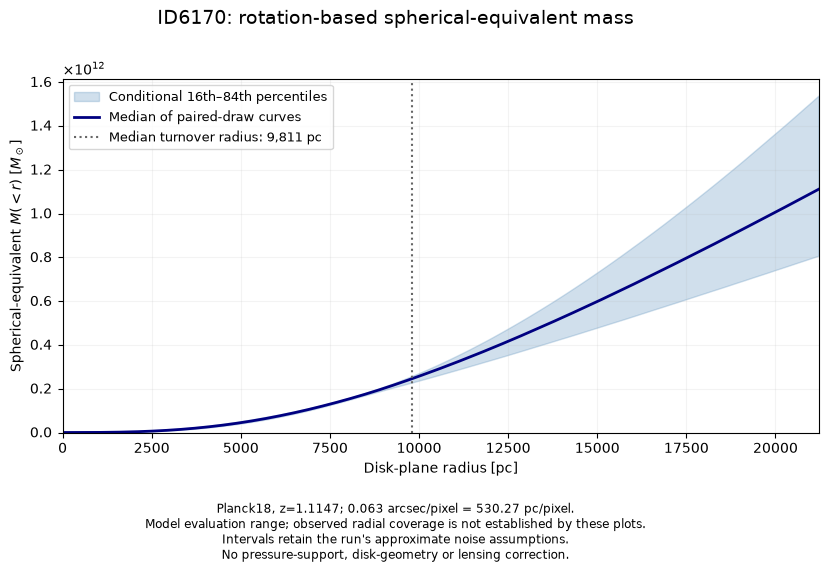

Saved turnover summary, rotation curve, dynamical mass, and physical_profiles.npz to: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/gaussian_center_s1_i75_centered_v450


In [13]:
fig = physical.mass_profile(radii_pc, save=True)
display(fig)
plt.close(fig)
print("Saved turnover summary, rotation curve, dynamical mass, and physical_profiles.npz to:", RESULT_DIR)